# Object detection with Faster R-CNN
Train a detector to find 20 kinds of objects in PASCAL VOC 2007. Then compare its boxes with the human annotations and save the model for your website.

**In Colab:** choose a GPU runtime and run all cells. The full run trains for 10 epochs. Choose **smoke** below to try one short epoch first. Results go to Google Drive. If the runtime disconnects, run the notebook again with the same settings to resume from the last completed epoch.

## 1. Choose your settings

In [1]:
MODE = "full"                # "full" for training, "smoke" for a quick check
BATCH_SIZE = 2               # Use 1 if your GPU runs out of memory
RUN_NAME = "voc07-head-v1"   # Choose a new name for a separate experiment
DISPLAY_THRESHOLD = 0.5      # Minimum confidence when drawing boxes
SEED = 42

assert MODE in ("full", "smoke")
EPOCHS = 10 if MODE == "full" else 1

In [2]:
import json
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision.datasets import VOCDetection
from torchvision.transforms.functional import to_tensor
from tqdm.auto import tqdm

in_colab = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if in_colab:
    from google.colab import drive
    drive.mount("/content/drive")
    base = Path("/content/drive/MyDrive/voc-detector")
else:
    base = Path.cwd() / "voc-detector"

RUN = base / RUN_NAME / MODE
RUN.mkdir(parents=True, exist_ok=True)
DATA = Path("/content/voc-data") if in_colab else Path.cwd() / "voc-data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print(f"{DEVICE} | {EPOCHS} epochs | saving to {RUN}")

Mounted at /content/drive
cuda | 10 epochs | saving to /content/drive/MyDrive/voc-detector/voc07-head-v1/full


## 2. Load the data
Each image can contain a different number of objects. The dataset returns an image tensor and its boxes and labels. The loader keeps images in a list so they can have different sizes.

In [3]:
CLASSES = (
    "__background__", "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor",
)
class_id = {name: index for index, name in enumerate(CLASSES)}

def read_target(annotation):
    boxes, labels, difficult = [], [], []
    for obj in annotation["annotation"].get("object", []):
        box = obj["bndbox"]
        # VOC starts counting pixels at 1. Convert to zero-based box edges.
        boxes.append([int(box["xmin"]) - 1, int(box["ymin"]) - 1,
                      int(box["xmax"]), int(box["ymax"])])
        labels.append(class_id[obj["name"]])
        difficult.append(bool(int(obj.get("difficult", 0))))
    return {
        "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        "labels": torch.tensor(labels, dtype=torch.int64),
        "difficult": torch.tensor(difficult, dtype=torch.bool),
    }

In [4]:
#@title Download and select images
from torchvision.datasets.utils import download_and_extract_archive

ARCHIVES = {
    "trainval": ("VOCtrainval_06-Nov-2007.tar", "c52e279531787c972589f7e41ab4ae64"),
    "test": ("VOCtest_06-Nov-2007.tar", "b6e924de25625d8de591ea690078ad9f"),
}

def load_split(split):
    group = "test" if split == "test" else "trainval"
    root = DATA / group
    files = root / "VOCdevkit/VOC2007/ImageSets/Main"
    marker = root / ".extract-in-progress"
    if marker.exists() or not (files / f"{split}.txt").exists():
        root.mkdir(parents=True, exist_ok=True)
        marker.touch()
        name, checksum = ARCHIVES[group]
        url = "https://thor.robots.ox.ac.uk/pascal/VOC/voc2007/" + name
        download_and_extract_archive(url, str(root), filename=name, md5=checksum)
        marker.unlink()

    data = VOCDetection(str(root), year="2007", image_set=split,
                        transform=to_tensor, target_transform=read_target)
    indices = list(range(len(data)))
    if MODE == "smoke":
        limit = 32 if split == "train" else 24
        indices = sorted(random.Random(SEED).sample(indices, min(limit, len(data))))
        if split == "train":
            rows = (files / "aeroplane_train.txt").read_text().splitlines()
            planes = {row.split()[0] for row in rows if row.split()[-1] == "1"}
            first_plane = next(i for i, path in enumerate(data.images) if Path(path).stem in planes)
            if first_plane not in indices:
                indices[-1] = first_plane
                indices.sort()
    return torch.utils.data.Subset(data, indices)

def image_ids(split):
    return [Path(split.dataset.images[i]).stem for i in split.indices]

def open_image(split, index):
    with Image.open(split.dataset.images[split.indices[index]]) as image:
        return image.convert("RGB")

In [5]:
def collate(batch):
    return tuple(zip(*batch))

def make_loader(dataset, shuffle=False, epoch=0):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED + epoch),
                      num_workers=2 if sys.platform.startswith("linux") else 0)

train_set = load_split("train")
val_set = load_split("val")
print(f"{len(train_set)} training images, {len(val_set)} validation images")

100%|██████████| 460M/460M [00:25<00:00, 18.0MB/s]


2501 training images, 2510 validation images


## 3. Prepare the model
Start with COCO-pretrained weights. Freeze the detector and replace its final predictor. It needs 21 outputs because TorchVision uses label 0 for background and labels 1–20 for the VOC objects.

In [6]:
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights, fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

MODEL_KWARGS = {"box_score_thresh": 0.01, "box_detections_per_img": 100}

def build_model():
    model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1,
                                     **MODEL_KWARGS)
    model.requires_grad_(False)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, len(CLASSES))
    return model

The next cell writes the small Python module the website will import. It rebuilds the same model from saved weights and returns box coordinates, class names and confidence scores.

In [7]:
%%writefile "{RUN}/voc_detector.py"
#@title Website prediction code
"""Standalone inference for the VOC 2007 Faster R-CNN checkpoint."""
import torch
from PIL import ImageOps
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.ops.misc import FrozenBatchNorm2d
from torchvision.transforms.functional import to_tensor


CLASSES = (
    "__background__", "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor",
)


def restore_detector(saved, device="cpu"):
    if saved["format_version"] != 1 or tuple(saved["classes"]) != CLASSES:
        raise ValueError("Incompatible detector checkpoint or class order.")
    # The COCO-v1 builder uses FrozenBatchNorm and changes its epsilon.
    # Recreate both explicitly so loading never needs a pretrained download.
    backbone = resnet_fpn_backbone(
        backbone_name="resnet50", weights=None, norm_layer=FrozenBatchNorm2d
    )
    model = FasterRCNN(backbone, num_classes=len(CLASSES), **saved["model_kwargs"])
    for layer in model.modules():
        if isinstance(layer, FrozenBatchNorm2d):
            layer.eps = saved["frozen_bn_eps"]
    model.load_state_dict(saved["state_dict"], strict=True)
    return model.to(device).eval()


def load_detector(checkpoint, device="cpu"):
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    return restore_detector(saved, device)


@torch.inference_mode()
def predict_image(model, image, threshold=0.5):
    """Return JSON-ready detections in EXIF-corrected, original-image pixels."""
    if not 0 <= threshold <= 1:
        raise ValueError("threshold must be between 0 and 1")
    image = ImageOps.exif_transpose(image).convert("RGB")
    device = next(model.parameters()).device
    output = model([to_tensor(image).to(device)])[0]
    keep = output["scores"] >= threshold
    boxes = output["boxes"][keep].cpu().tolist()
    labels = output["labels"][keep].cpu().tolist()
    scores = output["scores"][keep].cpu().tolist()
    return {
        "width": image.width, "height": image.height, "box_format": "xyxy",
        "detections": [
            {"class_id": label, "label": CLASSES[label], "score": score, "box": box}
            for box, label, score in zip(boxes, labels, scores)
        ],
    }

Overwriting /content/drive/MyDrive/voc-detector/voc07-head-v1/full/voc_detector.py


## 4. Train and save
For each batch, add the detector's four losses, backpropagate once, and update the predictor. After each epoch, average the losses and evaluate on validation images. The epoch with the highest validation mAP supplies the demo weights.

In [8]:
from collections import defaultdict

def train_one_epoch(model, loader, optimizer):
    model.train()
    totals = defaultdict(float)

    for images, targets in tqdm(loader, desc="Training"):
        images = [image.to(DEVICE) for image in images]
        targets = [{"boxes": t["boxes"].to(DEVICE), "labels": t["labels"].to(DEVICE)}
                   for t in targets]

        losses = model(images, targets)
        total_loss = sum(losses.values())
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        for name, value in losses.items():
            totals[name] += value.item()

    means = {name: value / len(loader) for name, value in totals.items()}
    return {"total": sum(means.values()), **means}

**Validation metric.** The evaluator uses VOC 2007 11-point average precision at IoU > 0.5. It ignores difficult objects and counts duplicate matches as false positives. The confidence slider only affects the displayed examples.

In [9]:
%%writefile "{RUN}/voc_metric.py"
#@title VOC 2007 average precision
import numpy as np


def match_image(pred_boxes, pred_labels, scores, gt_boxes, gt_labels, difficult):
    """VOC matching in zero-based edge coordinates. -1 ignored, 0 FP, 1 TP."""
    status = np.zeros(len(scores), dtype=np.int8)
    matched = np.zeros(len(gt_labels), dtype=bool)
    for label in np.unique(pred_labels):
        pred_idx = np.flatnonzero(pred_labels == label)
        gt_idx = np.flatnonzero(gt_labels == label)
        if len(gt_idx) == 0:
            continue
        p = pred_boxes[pred_idx]
        g = gt_boxes[gt_idx]
        lo = np.maximum(p[:, None, :2], g[None, :, :2])
        hi = np.minimum(p[:, None, 2:], g[None, :, 2:])
        intersection = np.maximum(hi - lo, 0).prod(axis=2)
        p_area = (p[:, 2:] - p[:, :2]).prod(axis=1)
        g_area = (g[:, 2:] - g[:, :2]).prod(axis=1)
        iou = intersection / np.maximum(p_area[:, None] + g_area - intersection, 1e-12)
        best = np.argmax(iou, axis=1)
        for row in np.argsort(-scores[pred_idx], kind="stable"):
            if iou[row, best[row]] <= 0.5:
                continue
            target = gt_idx[best[row]]
            index = pred_idx[row]
            if difficult[target]:
                status[index] = -1
            elif not matched[target]:
                status[index] = 1
                matched[target] = True
    return status, matched


class VOC2007Metric:
    def __init__(self, classes):
        self.classes = classes
        self.positives = np.zeros(len(classes), dtype=np.int64)
        self.records = [[] for _ in classes]

    def update(self, pred_boxes, pred_labels, scores, gt_boxes, gt_labels, difficult):
        status, _ = match_image(pred_boxes, pred_labels, scores, gt_boxes, gt_labels, difficult)
        self.positives += np.bincount(gt_labels[~difficult], minlength=len(self.classes))
        for label in np.unique(pred_labels):
            keep = (pred_labels == label) & (status >= 0)
            self.records[label].extend(zip(scores[keep].tolist(), status[keep].tolist()))

    def compute(self):
        result = {}
        for label, name in enumerate(self.classes[1:], start=1):
            count = int(self.positives[label])
            ap = None
            if count:
                ranked = sorted(self.records[label], key=lambda row: -row[0])
                hits = np.asarray([entry[1] for entry in ranked]).cumsum()
                recall = hits / count
                precision = hits / np.arange(1, len(hits) + 1)
                ap = float(np.mean([
                    precision[recall >= step / 10].max(initial=0.0) for step in range(11)
                ]))
            result[name] = {"positives": count, "ap": ap}
        values = [row["ap"] for row in result.values() if row["ap"] is not None]
        if not values:
            raise ValueError("The evaluation split has no non-difficult objects.")
        return {"map50_voc07": float(np.mean(values)), "classes_evaluated": len(values),
                "per_class": result}

Overwriting /content/drive/MyDrive/voc-detector/voc07-head-v1/full/voc_metric.py


In [10]:
import importlib

sys.path.insert(0, str(RUN))
import voc_detector
import voc_metric
importlib.reload(voc_detector)
importlib.reload(voc_metric)
assert tuple(CLASSES) == voc_detector.CLASSES

@torch.inference_mode()
def evaluate(model, dataset):
    model.eval()
    metric = voc_metric.VOC2007Metric(CLASSES)
    for images, targets in tqdm(make_loader(dataset), desc="Evaluating"):
        predictions = model([image.to(DEVICE) for image in images])
        for prediction, target in zip(predictions, targets):
            metric.update(prediction["boxes"].cpu().numpy(), prediction["labels"].cpu().numpy(),
                          prediction["scores"].cpu().numpy(), target["boxes"].numpy(),
                          target["labels"].numpy(), target["difficult"].numpy())
    return {"images": len(dataset), **metric.compute()}

In [11]:
#@title Run settings and checkpoint files
from importlib.metadata import version
from torchvision.ops.misc import FrozenBatchNorm2d

BEST, LATEST = RUN / "best.pt", RUN / "last.pt"
versions = {pkg: version(pkg) for pkg in ("torch", "torchvision", "numpy", "Pillow", "tqdm", "ipython")}
config = {"architecture": "fasterrcnn_resnet50_fpn", "initial_weights": "COCO_V1",
          "trainable": "roi_heads.box_predictor", "classes": list(CLASSES), "year": "2007",
          "mode": MODE, "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
          "lr": 0.005, "momentum": 0.9, "weight_decay": 0.0005, "model_kwargs": MODEL_KWARGS,
          "train_ids": image_ids(train_set), "val_ids": image_ids(val_set), "versions": versions}

def write_json(path, value):
    temp = path.with_suffix(".json.tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

config_path = RUN / "config.json"
if config_path.exists() and json.loads(config_path.read_text()) != config:
    raise ValueError("Settings changed. Choose a new RUN_NAME or restore the original settings.")
write_json(config_path, config)

def save_model(path, model, **details):
    temp = path.with_suffix(".pt.tmp")
    eps = next(layer.eps for layer in model.modules() if isinstance(layer, FrozenBatchNorm2d))
    torch.save({"format_version": 1, "classes": list(CLASSES), "model_kwargs": MODEL_KWARGS,
                "frozen_bn_eps": eps, "state_dict": model.state_dict(), **details}, temp)
    temp.replace(path)

In [12]:
# Continue an existing run, or initialize the detector once.
saved = torch.load(LATEST, map_location="cpu", weights_only=True) if LATEST.exists() else {}
model = voc_detector.restore_detector(saved, DEVICE) if saved else build_model().to(DEVICE)
model.requires_grad_(False)
predictor = model.roi_heads.box_predictor
predictor.requires_grad_(True)
optimizer = torch.optim.SGD(predictor.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)

history = saved.get("history", [])
best_score = saved.get("best_score", -1.0)
best_epoch = saved.get("best_epoch", 0)
best_head = saved.get("best_head")
if saved:
    optimizer.load_state_dict(saved["optimizer"])
    print(f"Resuming after epoch {len(history)}.")
del saved

Resuming after epoch 6.


In [13]:
for epoch in range(len(history) + 1, EPOCHS + 1):
    torch.manual_seed(SEED + epoch)
    start = time.perf_counter()
    losses = train_one_epoch(model, make_loader(train_set, shuffle=True, epoch=epoch), optimizer)
    validation = evaluate(model, val_set)
    score = validation["map50_voc07"]
    history.append({"epoch": epoch, "mean_batch_losses": losses, "validation": validation,
                    "seconds": time.perf_counter() - start})

    if score > best_score:
        best_epoch, best_score = epoch, score
        best_head = {k: v.detach().cpu().clone() for k, v in predictor.state_dict().items()}
        save_model(BEST, model, best_epoch=epoch, val_map50_voc07=score)

    save_model(LATEST, model, optimizer=optimizer.state_dict(), history=history,
               best_epoch=best_epoch, best_score=best_score, best_head=best_head)
    write_json(RUN / "history.json", history)
    print(f"Epoch {epoch}/{EPOCHS} | mean loss {losses['total']:.3f} | val mAP {score:.1%}")

# The backbone stayed frozen. Restoring the best head restores the selected detector.
predictor.load_state_dict(best_head)
save_model(BEST, model, best_epoch=best_epoch, val_map50_voc07=best_score)
write_json(RUN / "history.json", history)
print(f"Best model: epoch {best_epoch}, validation mAP {best_score:.1%}")

Training:   0%|          | 0/1251 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1255 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d89eb8c09a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d89eb8c09a0>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'
    AssertionErrorself._shutdown_workers(): 
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

Epoch 7/10 | mean loss 0.295 | val mAP 80.0%


Training:   0%|          | 0/1251 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1255 [00:00<?, ?it/s]

... (6 outputs left out)

Training:   0%|          | 0/1251 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1255 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d89eb8c09a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d89eb8c09a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 | mean loss 0.291 | val mAP 81.7%
Best model: epoch 10, validation mAP 81.7%


## 5. Test the saved model
Reload the selected checkpoint and evaluate the held-out test split. The report gives an AP for each class and their mean, mAP. Smoke-mode classes with no annotated objects have undefined AP.

In [14]:
import csv

model.cpu()
model = voc_detector.load_detector(BEST, DEVICE)
test_set = load_split("test")
metrics = evaluate(model, test_set)
write_json(RUN / "test_ids.json", image_ids(test_set))
write_json(RUN / "test_metrics.json", {**metrics, "mode": MODE, "best_epoch": best_epoch,
                                      "protocol": "VOC2007 11-point AP, IoU > 0.5"})
with (RUN / "per_class_ap.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["class", "non_difficult_objects", "AP50_VOC07"])
    for name, row in metrics["per_class"].items():
        writer.writerow([name, row["positives"], row["ap"]])
        score = "absent" if row["ap"] is None else f"{row['ap']:.1%}"
        print(f"{name:12} {score:>7}")
print(f"Test mAP: {metrics['map50_voc07']:.1%} on {len(test_set)} images ({MODE})")

100%|██████████| 451M/451M [00:25<00:00, 18.0MB/s]


Evaluating:   0%|          | 0/2476 [00:00<?, ?it/s]

aeroplane      89.3%
bicycle        85.0%
bird           82.8%
boat           72.2%
bottle         79.0%
bus            88.6%
car            88.4%
cat            86.3%
chair          65.7%
cow            87.8%
diningtable    77.5%
dog            82.3%
horse          87.7%
motorbike      86.8%
person         87.6%
pottedplant    60.8%
sheep          79.9%
sofa           79.5%
train          84.9%
tvmonitor      82.9%
Test mAP: 81.8% on 4952 images (full)


## 6. Look at the predictions
Change **IMAGE_INDEX** to inspect a different test image. The first panel shows the human annotations. The second shows the model's class labels and confidence scores.

In [15]:
from PIL import ImageDraw, ImageOps
from IPython.display import display

def draw_boxes(image, items, color):
    annotated = image.copy()
    draw = ImageDraw.Draw(annotated)
    for label, box in items:
        draw.rectangle(box, outline=color, width=3)
        draw.text((box[0] + 2, box[1] + 2), label, fill="white", stroke_width=2, stroke_fill="black")
    return annotated

def prediction_items(result):
    return [(f"{p['label']} {p['score']:.2f}", p["box"]) for p in result["detections"]
            if p["score"] >= DISPLAY_THRESHOLD]

def compare(image, truth, result):
    labels = [(g["label"] + (" (difficult)" if g["difficult"] else ""), g["box"]) for g in truth]
    left = draw_boxes(image, labels, "#19b57a")
    right = draw_boxes(image, prediction_items(result), "#ff922b")
    pair = Image.new("RGB", (2 * image.width, image.height + 22), "white")
    pair.paste(left, (0, 22))
    pair.paste(right, (image.width, 22))
    draw = ImageDraw.Draw(pair)
    draw.text((4, 4), "Ground truth", fill="black")
    draw.text((image.width + 4, 4), "Predictions", fill="black")
    return pair

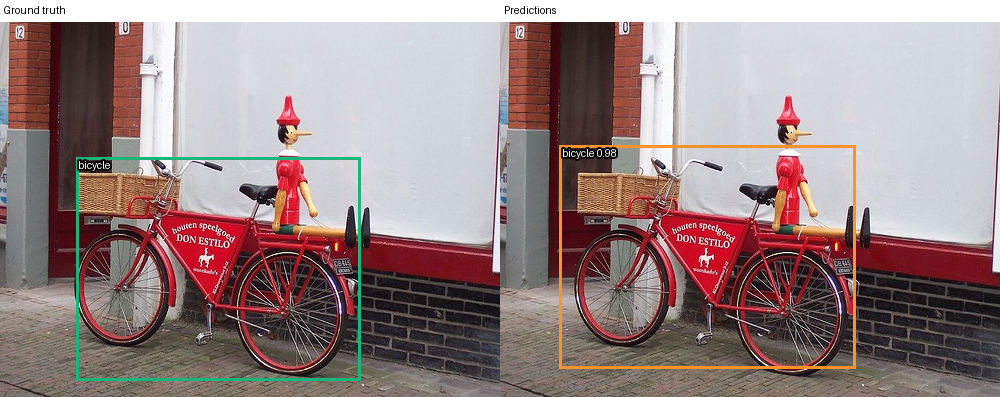

In [16]:
def inspect_image(index):
    image = open_image(test_set, index)
    _, target = test_set[index]
    truth = [{"label": CLASSES[label], "box": box, "difficult": difficult}
             for label, box, difficult in zip(target["labels"].tolist(),
                                              target["boxes"].tolist(), target["difficult"].tolist())]
    result = voc_detector.predict_image(model, image, threshold=0.0)
    return image, truth, result

IMAGE_INDEX = min(10, len(test_set) - 1)
image, truth, result = inspect_image(IMAGE_INDEX)
display(compare(image, truth, result))

**Try your own photo.** Set the path below to include your image and its real detections in the website bundle.

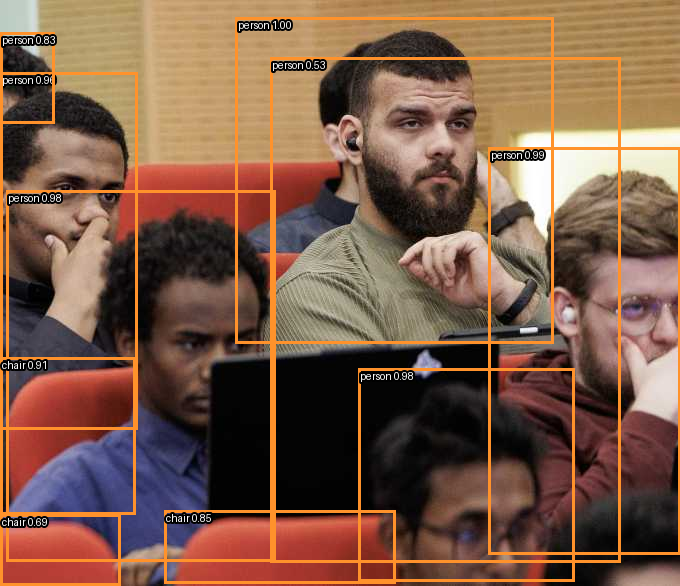

In [24]:
MY_IMAGE = ""  # e.g. "/content/my-photo.jpg"
if MY_IMAGE:
    with Image.open(MY_IMAGE) as original:
        photo = ImageOps.exif_transpose(original).convert("RGB")
    result = voc_detector.predict_image(model, photo, threshold=0.0)
    display(draw_boxes(photo, prediction_items(result), "#ff922b"))
    photo.save(RUN / "my-demo-input.png")
    write_json(RUN / "my-demo-result.json", result)

## 7. Save the website bundle
These last cells collect the examples and measurements. The ZIP contains the best model, the Python prediction module, real input/output pairs, and parameter counts for the animated stages. The training recovery file stays in your run folder.

The sample gallery looks for a correct detection, a false positive, and a missed object at the display threshold. It saves only the cases it finds. For the public website, use photos you own or can redistribute.

In [18]:
#@title Find example successes and errors
def classify_example(truth, result):
    shown = [p for p in result["detections"] if p["score"] >= DISPLAY_THRESHOLD]
    difficult = np.array([g["difficult"] for g in truth], dtype=bool)
    status, matched = voc_metric.match_image(
        np.array([p["box"] for p in shown]).reshape(-1, 4),
        np.array([p["class_id"] for p in shown], dtype=int),
        np.array([p["score"] for p in shown]),
        np.array([g["box"] for g in truth]).reshape(-1, 4),
        np.array([class_id[g["label"]] for g in truth], dtype=int), difficult)
    return {"correct_detection": bool((status == 1).any()), "false_positive": bool((status == 0).any()),
            "missed_object": bool((~matched & ~difficult).any())}

examples = RUN / "examples"
examples.mkdir(exist_ok=True)
cases, sample_files = {}, []
test_ids = image_ids(test_set)
for index in range(min(40, len(test_set))):
    image, truth, result = inspect_image(index)
    flags = classify_example(truth, result)
    new_cases = [name for name, found in flags.items() if found and name not in cases]
    if index == 0 or new_cases:
        image_id = test_ids[index]
        cases.update(dict.fromkeys(new_cases, image_id))
        image.save(examples / f"{image_id}.png")
        compare(image, truth, result).save(examples / f"{image_id}-comparison.jpg", quality=90)
        write_json(examples / f"{image_id}.json", {**result, "voc_id": image_id, "ground_truth": truth,
                   "cases": flags, "display_threshold": DISPLAY_THRESHOLD})
        sample_files.extend(f"examples/{image_id}{ext}" for ext in (".png", ".json", "-comparison.jpg"))
    if len(cases) == 3:
        break
write_json(examples / "index.json", {"found": cases, "scanned": index + 1,
                                    "display_threshold": DISPLAY_THRESHOLD})
print("Gallery examples:", cases)

Gallery examples: {'correct_detection': '000001', 'missed_object': '000001', 'false_positive': '000003'}


In [19]:
#@title Measure inference time
import platform

hardware = torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else platform.processor() or "CPU"
indices = random.Random(SEED).sample(range(len(test_set)), min(20, len(test_set)))
images = [open_image(test_set, index) for index in indices]
for image in images[:3]:
    voc_detector.predict_image(model, image, DISPLAY_THRESHOLD)

times = []
for image in images:
    start = time.perf_counter()
    # predict_image returns CPU values, so GPU work completes before the timer stops.
    voc_detector.predict_image(model, image, DISPLAY_THRESHOLD)
    times.append(1000 * (time.perf_counter() - start))
latency = {"device": str(DEVICE), "hardware": hardware, "batch_size": 1, "images": len(images),
           "ids": [test_ids[i] for i in indices], "warmup_images": len(images[:3]),
           "median_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95)),
           "individual_ms": times}
write_json(RUN / "latency.json", latency)
print(f"Median prediction time: {latency['median_ms']:.0f} ms on {hardware}")

Median prediction time: 24 ms on NVIDIA A100-SXM4-40GB


In [20]:
#@title Record the environment and the model stages
import hashlib

stages = {"backbone": model.backbone.body, "feature_pyramid": model.backbone.fpn,
          "region_proposals": model.rpn, "roi_pool": model.roi_heads.box_roi_pool,
          "box_head": model.roi_heads.box_head, "predictor": model.roi_heads.box_predictor}
digest = hashlib.sha256()
with BEST.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        digest.update(chunk)
write_json(RUN / "manifest.json", {
    "format_version": 1, "architecture": config["architecture"], "checkpoint": BEST.name,
    "sha256": digest.hexdigest(), "classes": list(CLASSES), "mode": MODE,
    "best_epoch": best_epoch, "validation_map50_voc07": best_score,
    "test_map50_voc07": metrics["map50_voc07"], "output_coordinates": "xyxy in oriented original image pixels",
    "stage_parameters": {name: sum(p.numel() for p in stage.parameters()) for name, stage in stages.items()},
})
write_json(RUN / "environment.json", {"python": sys.version, "platform": platform.platform(),
           "hardware": hardware, "device": str(DEVICE), "cuda_runtime": torch.version.cuda, "packages": versions})
requirements = [f"{name}=={versions[name]}" for name in ("torch", "torchvision", "Pillow")]
(RUN / "inference-requirements.txt").write_text("\n".join(requirements) + "\n", encoding="utf-8")

61

In [21]:
from zipfile import ZipFile

files = ["best.pt", "voc_detector.py", "voc_metric.py", "manifest.json", "config.json",
         "history.json", "test_metrics.json", "test_ids.json", "per_class_ap.csv", "latency.json",
         "environment.json", "inference-requirements.txt", "examples/index.json", *sample_files]
if MY_IMAGE:
    files += ["my-demo-input.png", "my-demo-result.json"]

bundle = RUN / f"voc-detector-{MODE}.zip"
temp = bundle.with_suffix(".zip.tmp")
with ZipFile(temp, "w") as archive:
    for name in files:
        archive.write(RUN / name, name)
temp.replace(bundle)
print("Website bundle:", bundle)
print("Resume checkpoint:", LATEST)

Website bundle: /content/drive/MyDrive/voc-detector/voc07-head-v1/full/voc-detector-full.zip
Resume checkpoint: /content/drive/MyDrive/voc-detector/voc07-head-v1/full/last.pt


**Use the model after unzipping.** Run these lines from the extracted folder in an environment with the recorded PyTorch, TorchVision and Pillow versions.

```python
from PIL import Image
from voc_detector import load_detector, predict_image

model = load_detector("best.pt")
with Image.open("your-photo.jpg") as photo:
    result = predict_image(model, photo, threshold=0.5)
print(result["detections"])
```

[PyTorch fine-tuning tutorial](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html) · [VOC 2007 evaluation protocol](https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2007/htmldoc/)